In [1]:
import os
import random
import numpy as np
import pandas as pd
import cv2
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import itertools

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import EfficientNetB7
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess

# إصلاح توافقية np.bool مع NumPy 2.x
if not hasattr(np, 'bool'):
    np.bool = bool

import albumentations as A

# ================================================================
# 1. Parameter Settings
# ================================================================
DATASET_PATH_1 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1'
DATASET_PATH_2 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2'
METADATA_CSV = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv'

IMG_SIZE = 224
BATCH_SIZE = 32
RANDOM_STATE = 42
EPOCHS = 30

TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-6

# Set random seed for reproducibility
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ================================================================
# 2. Load Metadata and Image Paths
# ================================================================
meta_df = pd.read_csv(METADATA_CSV)
imageid_to_label = dict(zip(meta_df['image_id'], meta_df['dx']))

image_files_1 = sorted(os.listdir(DATASET_PATH_1))
image_files_2 = sorted(os.listdir(DATASET_PATH_2))
all_image_files = image_files_1 + image_files_2

rows = []
for fname in tqdm(all_image_files, desc='Listing images'):
    image_id = os.path.splitext(fname)[0]
    label = imageid_to_label.get(image_id)
    if label is None: 
        continue
    if fname in image_files_1:
        full = os.path.join(DATASET_PATH_1, fname)
    else:
        full = os.path.join(DATASET_PATH_2, fname)
    rows.append((full, label))

df = pd.DataFrame(rows, columns=['path', 'label'])
print("Total images found:", len(df))

# Encode string labels to integers
le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])
num_classes = len(le.classes_)
print("Classes:", list(le.classes_))

# ================================================================
# 3. Stratified Dataset Split (70% Train / 15% Val / 15% Test)
# ================================================================
train_and_val, test_df = train_test_split(
    df, test_size=TEST_RATIO, stratify=df['label_enc'], random_state=RANDOM_STATE
)
relative_val_ratio = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
train_df, val_df = train_test_split(
    train_and_val, test_size=relative_val_ratio, stratify=train_and_val['label_enc'], random_state=RANDOM_STATE
)

print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df)}")

# ================================================================
# 4. Image Preprocessing Transformation (No Augmentation)
# ================================================================
base_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE)
])

def load_image(path, transform=None):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if transform:
        img = transform(image=img)["image"]
    else:
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return efficientnet_preprocess(img.astype(np.float32))

# ================================================================
# 5. Data Generator Class
# ================================================================
class EfficientNetB7OnlyGenerator(tf.keras.utils.Sequence):
    def __init__(self, df, batch_size=32, transform=None, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.transform = transform
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_paths = self.df.loc[batch_idx, "path"].values
        batch_labels = self.df.loc[batch_idx, "label_enc"].values
        
        imgs = [load_image(path, transform=self.transform) for path in batch_paths]
        imgs = np.stack(imgs, axis=0)
        y = tf.keras.utils.to_categorical(batch_labels, num_classes=num_classes)
        return imgs, y

train_gen = EfficientNetB7OnlyGenerator(train_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=True)
val_gen = EfficientNetB7OnlyGenerator(val_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=False)
test_gen = EfficientNetB7OnlyGenerator(test_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=False)

# ================================================================
# 6. Build EfficientNetB7 Only Model
# ================================================================
def build_efficientnetb7_only(num_classes, img_size=224):
    img_input = layers.Input(shape=(img_size, img_size, 3), name='image_input')
    
    # EfficientNetB7 Backbone
    base_model = EfficientNetB7(include_top=False, input_tensor=img_input, weights='imagenet')
    
    # Classification Head
    x = layers.GlobalAveragePooling2D()(base_model.output)
    out = layers.Dense(num_classes, activation='softmax', name='output')(x)
    
    model = models.Model(inputs=img_input, outputs=out, name='EfficientNetB7_Only')
    return model, base_model

model, base_model = build_efficientnetb7_only(num_classes, IMG_SIZE)

# Unfreeze backbone layers for full fine-tuning
for layer in base_model.layers:
    layer.trainable = True

model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# ================================================================
# 7. Model Training
# ================================================================
checkpoint_path = "efficientnetb7_only_best.h5"
cb = [
    callbacks.ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

print("\n>>> Starting EfficientNetB7 Only Training <<<\n")
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=cb
)

# ================================================================
# 8. Evaluation on Test Set
# ================================================================
print("\n>>> Evaluating Best Model on Test Set <<<")
model.load_weights(checkpoint_path)

y_true = []
y_pred_probs = []

for i in range(len(test_gen)):
    imgs, y_batch = test_gen[i]
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(y_batch, axis=1))
    y_pred_probs.extend(preds)

y_pred = np.argmax(y_pred_probs, axis=1)

print("\n--- Test Accuracy ---")
test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=le.classes_))

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_true, y_pred))

Listing images: 100%|██████████| 10015/10015 [00:00<00:00, 19552.33it/s]


Total images found: 10015
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Train samples: 7009 | Val samples: 1503 | Test samples: 1503


I0000 00:00:1789276624.061132      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789276624.064318      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


258076736/258076736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "EfficientNetB7_Only"

...


Epoch 9: finished saving model to efficientnetb7_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 231s 1s/step - accuracy: 0.9944 - loss: 0.0166 - val_accuracy: 0.8589 - val_loss: 0.5961 - learning_rate: 5.0000e-05
Epoch 10/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 961ms/step - accuracy: 0.9973 - loss: 0.0115
Epoch 10: val_accuracy did not improve from 0.85895
220/220 ━━━━━━━━━━━━━━━━━━━━ 226s 1s/step - accuracy: 0.9966 - loss: 0.0132 - val_accuracy: 0.8589 - val_loss: 0.5835 - learning_rate: 5.0000e-05
Epoch 11/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 960ms/step - accuracy: 0.9988 - loss: 0.0084
Epoch 11: val_accuracy improved from 0.85895 to 0.86294, saving model to efficientnetb7_only_best.h5



Epoch 11: finished saving model to efficientnetb7_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 229s 1s/step - accuracy: 0.9979 - loss: 0.0100 - val_accuracy: 0.8629 - val_loss: 0.5535 - learning_rate: 5.0000e-05
Epoch 12/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 961ms/step - accuracy: 0.9975 - loss: 0.0086
Epoch 12: val_accuracy did not improve from 0.86294

Epoch 12: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
220/220 ━━━━━━━━━━━━━━━━━━━━ 226s 1s/step - accuracy: 0.9976 - loss: 0.0084 - val_accuracy: 0.8623 - val_loss: 0.6134 - learning_rate: 5.0000e-05
Epoch 13/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 961ms/step - accuracy: 0.9980 - loss: 0.0083
Epoch 13: val_accuracy did not improve from 0.86294
220/220 ━━━━━━━━━━━━━━━━━━━━ 225s 1s/step - accuracy: 0.9986 - loss: 0.0070 - val_accuracy: 0.8616 - val_loss: 0.5997 - learning_rate: 2.5000e-05
Epoch 14/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 963ms/step - accuracy: 0.9985 - loss: 0.0053
Epoch 14: val_accuracy improved from 0.86294 to 0


Epoch 14: finished saving model to efficientnetb7_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 230s 1s/step - accuracy: 0.9973 - loss: 0.0078 - val_accuracy: 0.8663 - val_loss: 0.6115 - learning_rate: 2.5000e-05
Epoch 15/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 963ms/step - accuracy: 0.9986 - loss: 0.0061
Epoch 15: val_accuracy improved from 0.86627 to 0.86826, saving model to efficientnetb7_only_best.h5



Epoch 15: finished saving model to efficientnetb7_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 230s 1s/step - accuracy: 0.9986 - loss: 0.0062 - val_accuracy: 0.8683 - val_loss: 0.5981 - learning_rate: 2.5000e-05
Epoch 16/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 962ms/step - accuracy: 0.9985 - loss: 0.0057
Epoch 16: val_accuracy did not improve from 0.86826
220/220 ━━━━━━━━━━━━━━━━━━━━ 227s 1s/step - accuracy: 0.9989 - loss: 0.0056 - val_accuracy: 0.8603 - val_loss: 0.6180 - learning_rate: 2.5000e-05
Epoch 17/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 959ms/step - accuracy: 0.9997 - loss: 0.0025
Epoch 17: val_accuracy did not improve from 0.86826

Epoch 17: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-05.
220/220 ━━━━━━━━━━━━━━━━━━━━ 225s 1s/step - accuracy: 0.9994 - loss: 0.0028 - val_accuracy: 0.8683 - val_loss: 0.6362 - learning_rate: 2.5000e-05
Epoch 18/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 963ms/step - accuracy: 0.9988 - loss: 0.0051
Epoch 18: val_accuracy did not improve from 0.868


Epoch 22: finished saving model to efficientnetb7_only_best.h5

Epoch 22: ReduceLROnPlateau reducing learning rate to 6.24999984211172e-06.
220/220 ━━━━━━━━━━━━━━━━━━━━ 230s 1s/step - accuracy: 0.9990 - loss: 0.0034 - val_accuracy: 0.8689 - val_loss: 0.6351 - learning_rate: 1.2500e-05
Epoch 23/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 964ms/step - accuracy: 0.9997 - loss: 0.0023
Epoch 23: val_accuracy did not improve from 0.86893
220/220 ━━━━━━━━━━━━━━━━━━━━ 226s 1s/step - accuracy: 0.9996 - loss: 0.0025 - val_accuracy: 0.8636 - val_loss: 0.6420 - learning_rate: 6.2500e-06
Epoch 24/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 962ms/step - accuracy: 0.9998 - loss: 0.0014
Epoch 24: val_accuracy did not improve from 0.86893
220/220 ━━━━━━━━━━━━━━━━━━━━ 225s 1s/step - accuracy: 0.9999 - loss: 0.0014 - val_accuracy: 0.8669 - val_loss: 0.6454 - learning_rate: 6.2500e-06
Epoch 25/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 962ms/step - accuracy: 0.9994 - loss: 0.0027
Epoch 25: val_accuracy did not improve from 0.8689

Test Accuracy: 87.03%
Classification Report:
               precision    recall  f1-score   support

       akiec     0.7021    0.6735    0.6875        49
         bcc     0.8594    0.7143    0.7801        77
         bkl     0.7958    0.6848    0.7362       165
          df     0.6923    0.5294    0.6000        17
         mel     0.7939    0.6228    0.6980       167
          nv     0.9001    0.9672    0.9324      1006
        vasc     0.8400    0.9545    0.8936        22

    accuracy                         0.8703      1503
   macro avg     0.7977    0.7352    0.7611      1503
weighted avg     0.8651    0.8703    0.8647      1503



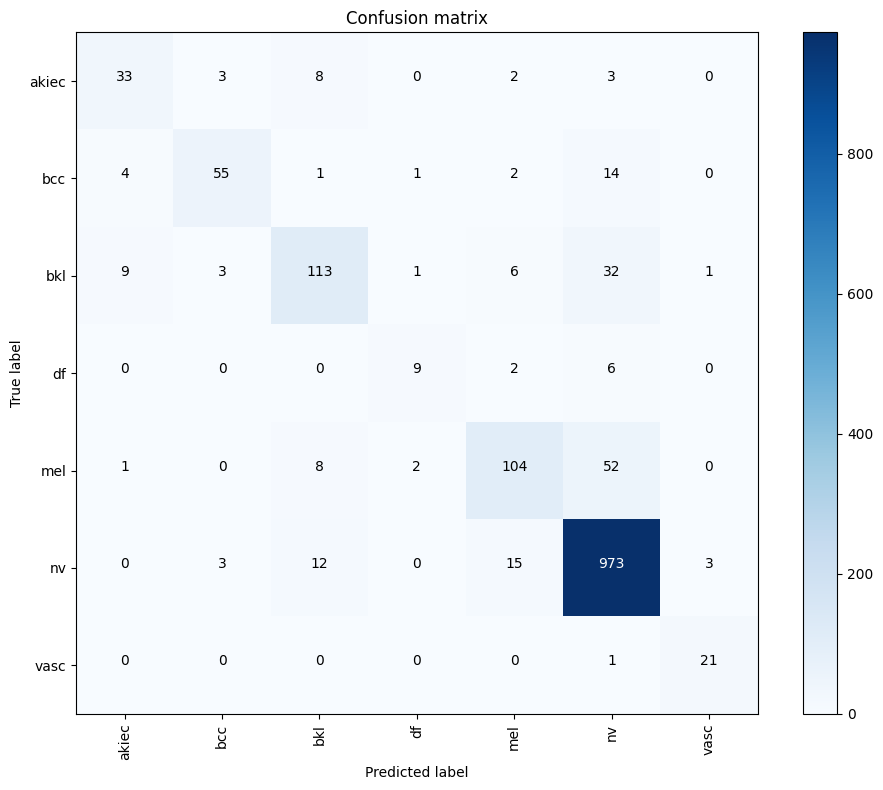

In [2]:
# ================================================================
# Evaluation - Safe Version
# ================================================================
def get_preds_safe(generator):
    """Collect predictions from generator safely"""
    preds, labels = [], []
    n_batches = len(generator)
    
    for i in range(n_batches):
        try:
            X, y = generator[i]
            if isinstance(X, tuple):
                p = model.predict(X, verbose=0)
            else:
                p = model.predict(X, verbose=0)
            preds.append(p)
            labels.append(y)
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not preds:
        return np.array([]), np.array([])
    
    return np.vstack(preds), np.vstack(labels)

preds, true = get_preds_safe(test_gen)
pred_labels = np.argmax(preds, axis=1)
true_labels = np.argmax(true, axis=1)

acc = accuracy_score(true_labels, pred_labels)
print(f"Test Accuracy: {acc*100:.2f}%")
print("Classification Report:\n", classification_report(true_labels, pred_labels, target_names=le.classes_, digits=4))

cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(10,8))
plt.imshow(cm, cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.colorbar()
plt.xticks(np.arange(len(le.classes_)), le.classes_, rotation=90)
plt.yticks(np.arange(len(le.classes_)), le.classes_)
thresh = cm.max() / 2
for i,j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j,i,cm[i,j], ha="center", color="white" if cm[i,j]>thresh else "black")
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

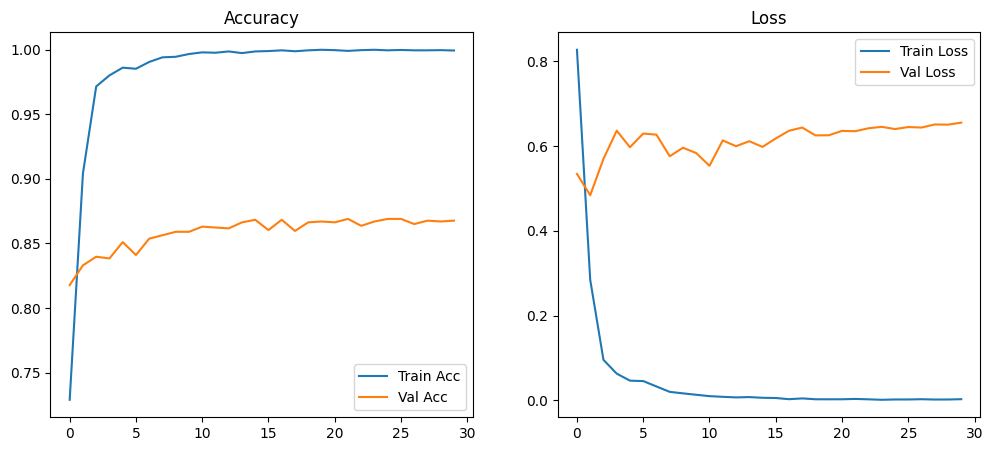

In [3]:
# ================================================================
# Training curves
# ================================================================
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Accuracy")
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.legend()
plt.show()

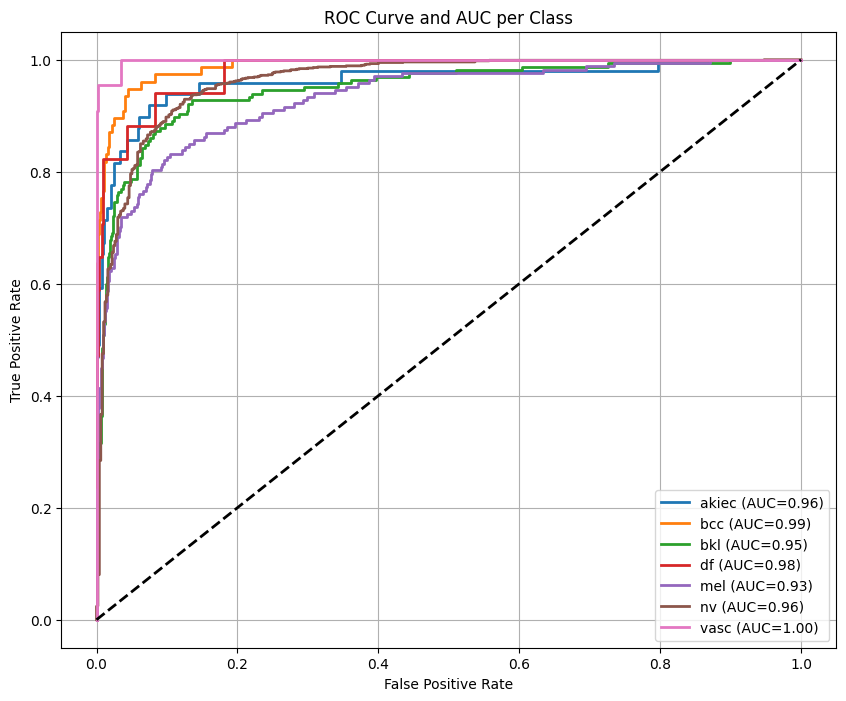

AUC for akiec: 0.9622
AUC for bcc: 0.9887
AUC for bkl: 0.9490
AUC for df: 0.9798
AUC for mel: 0.9323
AUC for nv: 0.9620
AUC for vasc: 0.9982
weighted-average AUC: 0.9823


In [4]:
# ================================================================
# ROC Curves - Safe Version
# ================================================================
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def collect_predictions_for_roc(generator, model, num_batches=None):
    """Collect predictions from generator safely for ROC"""
    y_true_list = []
    y_pred_list = []
    
    n_batches = len(generator)
    if num_batches is not None:
        n_batches = min(n_batches, n_batches)
    
    if n_batches == 0:
        print(" Warning: Generator has no batches!")
        return np.array([]), np.array([])
    
    for i in range(n_batches):
        try:
            batch_x, batch_y = generator[i]
            
            if isinstance(batch_x, tuple):
                batch_pred = model.predict(batch_x, verbose=0)
            else:
                batch_pred = model.predict(batch_x, verbose=0)
            
            y_true_list.append(batch_y)
            y_pred_list.append(batch_pred)
            
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not y_true_list:
        print(" No predictions collected!")
        return np.array([]), np.array([])
    
    return np.concatenate(y_true_list, axis=0), np.concatenate(y_pred_list, axis=0)

y_true, y_pred = collect_predictions_for_roc(test_gen, model)

if y_true.size == 0 or y_pred.size == 0:
    print(" Failed to collect predictions, skipping ROC Curves")
else:
    if y_true.ndim == 2:
        y_true_indices = np.argmax(y_true, axis=1)
    else:
        y_true_indices = y_true

    n_classes = y_pred.shape[1]
    class_names = le.classes_

    y_true_bin = label_binarize(y_true_indices, classes=range(n_classes))

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fpr["weighted"], tpr["weighted"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
    roc_auc["weighted"] = auc(fpr["weighted"], tpr["weighted"])

    plt.figure(figsize=(10, 8))
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], lw=2, label=f"{class_names[i]} (AUC={roc_auc[i]:.2f})")

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve and AUC per Class")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

    for i in range(n_classes):
        print(f"AUC for {class_names[i]}: {roc_auc[i]:.4f}")
    print(f"weighted-average AUC: {roc_auc['weighted']:.4f}")

In [5]:
# ================================================================
# Complete Metrics
# ================================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

precision = precision_score(true_labels, pred_labels, average="weighted")
sensitivity = recall_score(true_labels, pred_labels, average="weighted")
f1 = f1_score(true_labels, pred_labels, average="weighted")

cm = confusion_matrix(true_labels, pred_labels)
TN = []
FP = []
for i in range(len(cm)):
    tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
    fp = np.sum(cm[:, i]) - cm[i, i]
    TN.append(tn)
    FP.append(fp)
specificity = np.mean(np.array(TN) / (np.array(TN) + np.array(FP)))

auc_score = roc_auc_score(true_labels, preds, multi_class="ovr", average="weighted")

print("="*50)
print(" COMPLETE METRICS SUMMARY")
print("="*50)
print(f" Accuracy    : {acc*100:.2f}%")
print(f" Specificity : {specificity*100:.2f}%")
print(f" Precision   : {precision*100:.2f}%")
print(f" Sensitivity : {sensitivity*100:.2f}%")
print(f" F1 Score    : {f1*100:.2f}%")
print("="*50)

 COMPLETE METRICS SUMMARY
 Accuracy    : 87.03%
 Specificity : 95.99%
 Precision   : 86.51%
 Sensitivity : 87.03%
 F1 Score    : 86.47%
